# 05 — Modèle multivarié

**Entrée** : `data/processed/co2_clean.csv`  
Prédiction du CO₂ par habitant avec plusieurs variables explicatives (régression linéaire et Random Forest).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("../data/processed/co2_clean.csv")

df.head()

,country,iso_code,year,population,gdp,co2,co2_per_capita,cumulative_co2,co2_growth_prct,coal_co2,oil_co2,gas_co2,land_use_change_co2,methane,nitrous_oxide,temperature_change_from_co2,temperature_change_from_ghg
0,Afghanistan,AFG,1949,7356890.0,NaN,0.014656,0.001992,0.014656,NaN,0.014656,0.000000,0.0,6.102172,7.729318,2.162319,0.000307,0.000528
1,Afghanistan,AFG,1950,7776180.0,9.421400e+09,0.084272,0.010837,0.098928,475.000000,0.021068,0.063204,0.0,7.084747,7.879157,2.230887,0.000311,0.000538
2,Afghanistan,AFG,1951,7879343.0,9.692280e+09,0.091600,0.011625,0.190528,8.695650,0.025648,0.065952,0.0,8.000418,7.972563,2.292099,0.000316,0.000548
3,Afghanistan,AFG,1952,7987784.0,1.001732e+10,0.091600,0.011468,0.282128,0.000000,0.031708,0.059892,0.0,8.913743,8.072992,2.365288,0.000321,0.000560
4,Afghanistan,AFG,1953,8096703.0,1.063052e+10,0.106256,0.013123,0.388384,15.999996,0.037949,0.068307,0.0,9.963808,8.185520,2.446641,0.000327,0.000571


In [3]:
df.columns

Index(['country', 'iso_code', 'year', 'population', 'gdp', 'co2',
       'co2_per_capita', 'cumulative_co2', 'co2_growth_prct', 'coal_co2',
       'oil_co2', 'gas_co2', 'land_use_change_co2', 'methane', 'nitrous_oxide',
       'temperature_change_from_co2', 'temperature_change_from_ghg'],
      dtype='str')

In [47]:
# PIB par habitant
df["gdp_per_capita"] = df["gdp"] / df["population"]

# Part des combustibles fossiles
df["fossil_share"] = (
    df["coal_co2"] + df["oil_co2"] + df["gas_co2"]
) / df["co2"]

# Remplacer les valeurs infinies
df["fossil_share"] = df["fossil_share"].replace(
    [np.inf, -np.inf], np.nan
)

df[[
    "country",
    "year",
    "population",
    "gdp_per_capita",
    "fossil_share",
    "co2_per_capita"
]].head()

,country,year,population,gdp_per_capita,fossil_share,co2_per_capita
0,Afghanistan,1949,7356890.0,NaN,1.0,0.001992
1,Afghanistan,1950,7776180.0,1211.571749,1.0,0.010837
2,Afghanistan,1951,7879343.0,1230.087331,1.0,0.011625
3,Afghanistan,1952,7987784.0,1254.080606,1.0,0.011468
4,Afghanistan,1953,8096703.0,1312.944293,1.0,0.013123


In [48]:
variables = [
    "year",
    "population",
    "gdp_per_capita",
    "fossil_share",
    "co2_per_capita"
]

# Nombre d'observations complètes par pays
country_stats = (
    df.groupby("country")[variables]
      .apply(lambda x: x.notna().all(axis=1).sum())
      .sort_values(ascending=False)
)

# Garder les pays ayant au moins 20 observations complètes
valid_countries = country_stats[
    country_stats >= 20
].index

df_model = df[
    df["country"].isin(valid_countries)
].dropna(
    subset=variables
).copy()

print("Nombre de pays :", df_model["country"].nunique())
print("Nombre de lignes :", len(df_model))

Nombre de pays : 106
Nombre de lignes : 7513


In [49]:
# Entraînement : jusqu'à 2015
train = df_model[
    df_model["year"] <= 2015
].copy()

# Test : après 2015
test = df_model[
    df_model["year"] > 2015
].copy()

features = [
    "year",
    "population",
    "gdp_per_capita",
    "fossil_share"
]

target = "co2_per_capita"

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Train :", len(train))
print("Test :", len(test))
print("Période train :", train["year"].min(), "→", train["year"].max())
print("Période test :", test["year"].min(), "→", test["year"].max())

Train : 6815
Test : 698
Période train : 1900 → 2015
Période test : 2016 → 2022


In [50]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [51]:
y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = rf_model.score(X_test, y_test)

print("===== PERFORMANCE DU MODÈLE FINAL =====")
print("MAE :", round(mae, 4))
print("RMSE :", round(rmse, 4))
print("R² :", round(r2, 4))

===== PERFORMANCE DU MODÈLE FINAL =====
MAE : 2.3568
RMSE : 3.7027
R² : 0.5836


In [52]:
feature_importance = pd.DataFrame({
    "Variable": features,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Variable,Importance
2,gdp_per_capita,0.544789
1,population,0.274904
3,fossil_share,0.108130
0,year,0.072178


In [53]:
future_data = []

for country in valid_countries:

    country_df = (
        df_model[df_model["country"] == country]
        .sort_values("year")
    )

    last = country_df.iloc[-1]

    population_2024 = last["population"]
    gdp_2024 = last["gdp_per_capita"]
    fossil_2024 = last["fossil_share"]

    # Croissance historique moyenne
    pop_growth = country_df["population"].pct_change().mean()
    gdp_growth = country_df["gdp_per_capita"].pct_change().mean()

    # Limitation des valeurs extrêmes
    pop_growth = np.clip(pop_growth, -0.02, 0.05)
    gdp_growth = np.clip(gdp_growth, -0.05, 0.08)

    for year in range(2025, 2041):

        n = year - 2024

        # Population
        population_future = (
            population_2024 * (1 + pop_growth) ** n
        )

        # =========================
        # SCÉNARIO 1 : CONTINUITÉ
        # =========================
        gdp_continuity = (
            gdp_2024 * (1 + gdp_growth) ** n
        )

        fossil_continuity = fossil_2024

        # =========================
        # SCÉNARIO 2 : TRANSITION
        # =========================
        gdp_transition = (
            gdp_2024 * (1 + gdp_growth) ** n
        )

        fossil_transition = max(
            fossil_2024 * (0.98 ** n),
            0
        )

        # =========================
        # SCÉNARIO 3 : FORTE CROISSANCE
        # =========================
        gdp_high = (
            gdp_2024 *
            (1 + gdp_growth + 0.01) ** n
        )

        fossil_high = fossil_2024

        future_data.extend([
            [
                country,
                year,
                "Continuité",
                population_future,
                gdp_continuity,
                fossil_continuity
            ],
            [
                country,
                year,
                "Transition énergétique",
                population_future,
                gdp_transition,
                fossil_transition
            ],
            [
                country,
                year,
                "Forte croissance",
                population_future,
                gdp_high,
                fossil_high
            ]
        ])

future_scenarios = pd.DataFrame(
    future_data,
    columns=[
        "country",
        "year",
        "scenario",
        "population",
        "gdp_per_capita",
        "fossil_share"
    ]
)

print("Pays :", future_scenarios["country"].nunique())
print("Lignes :", len(future_scenarios))

future_scenarios.head()

Pays : 106
Lignes : 5088


,country,year,scenario,population,gdp_per_capita,fossil_share
0,Belgium,2025,Continuité,1.169461e+07,42781.779205,0.950823
1,Belgium,2025,Transition énergétique,1.169461e+07,42781.779205,0.931807
2,Belgium,2025,Forte croissance,1.169461e+07,43202.399561,0.950823
3,Belgium,2026,Continuité,1.174765e+07,43513.838735,0.950823
4,Belgium,2026,Transition énergétique,1.174765e+07,43513.838735,0.913171


In [54]:
X_future = future_scenarios[features]

future_scenarios["predicted_co2_per_capita"] = (
    rf_model.predict(X_future)
)

future_scenarios.head()

,country,year,scenario,population,gdp_per_capita,fossil_share,predicted_co2_per_capita
0,Belgium,2025,Continuité,1.169461e+07,42781.779205,0.950823,13.096505
1,Belgium,2025,Transition énergétique,1.169461e+07,42781.779205,0.931807,12.493256
2,Belgium,2025,Forte croissance,1.169461e+07,43202.399561,0.950823,13.717976
3,Belgium,2026,Continuité,1.174765e+07,43513.838735,0.950823,14.354074
4,Belgium,2026,Transition énergétique,1.174765e+07,43513.838735,0.913171,13.023527


In [55]:
scenario_global = (
    future_scenarios
    .groupby(["year", "scenario"])
    ["predicted_co2_per_capita"]
    .mean()
    .reset_index()
)

scenario_global.head()

,year,scenario,predicted_co2_per_capita
0,2025,Continuité,8.275375
1,2025,Forte croissance,8.389734
2,2025,Transition énergétique,8.376774
3,2026,Continuité,8.566604
4,2026,Forte croissance,8.701578


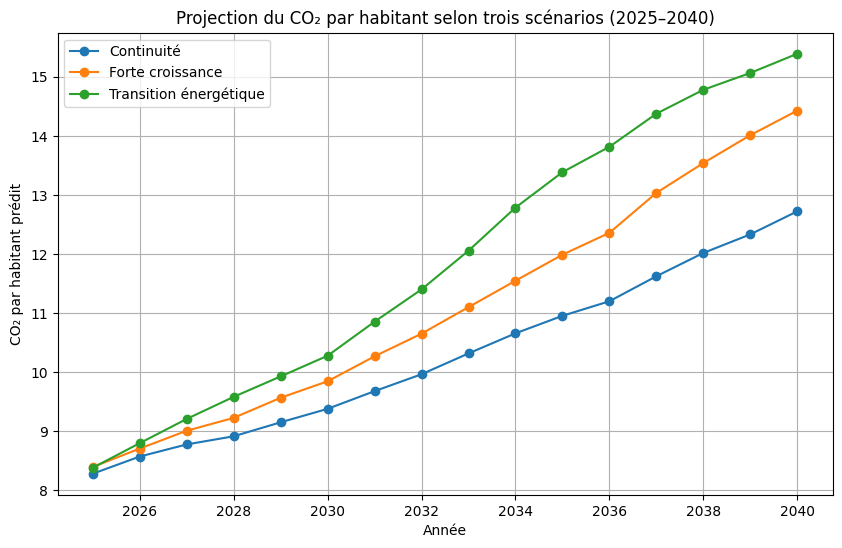

In [56]:
plt.figure(figsize=(10, 6))

for scenario in scenario_global["scenario"].unique():

    data = scenario_global[
        scenario_global["scenario"] == scenario
    ]

    plt.plot(
        data["year"],
        data["predicted_co2_per_capita"],
        marker="o",
        label=scenario
    )

plt.xlabel("Année")
plt.ylabel("CO₂ par habitant prédit")
plt.title(
    "Projection du CO₂ par habitant selon trois scénarios (2025–2040)"
)

plt.legend()
plt.grid(True)
plt.show()

In [57]:
print("===== PROJECTIONS 2025–2040 =====")
print("Nombre de pays :", future_scenarios["country"].nunique())
print("Nombre de lignes :", len(future_scenarios))
print(
    "Période :",
    future_scenarios["year"].min(),
    "→",
    future_scenarios["year"].max()
)

===== PROJECTIONS 2025–2040 =====
Nombre de pays : 106
Nombre de lignes : 5088
Période : 2025 → 2040
